# Análise CRISP-DM: Campanhas de Marketing — Case iFood
**Disciplina:** Ciência de Dados aplicada ao Marketing — CEUB
**Professora:** Kadidja Valéria Reginaldo de Oliveira
**Integrantes (Grupo 1):** Greyci Dias, Maria Antônia e Lucas Rogoski

Base de dados: case de CRM que o iFood usa em seus processos seletivos (2.240 clientes).

## Fase 1 — Compreensão do Negócio

**Contexto:** a empresa do case é um varejista de alimentos que vende vinhos, carnes, frutas, peixes e doces por três canais: loja física, catálogo e site. O lucro está estagnado, e a empresa quer melhorar o desempenho das suas campanhas de marketing.

**Problema:** na campanha piloto (campanha 6), a empresa ligou para 2.240 clientes escolhidos ao acaso para vender um produto novo. Só 15% aceitaram. A campanha custou 6.720, rendeu 3.674 e gerou **prejuízo de 3.046** unidades monetárias.

**Objetivo:** descobrir o perfil de quem aceita a campanha e criar um modelo que preveja quais clientes têm mais chance de aceitar. Assim, a empresa liga só para eles.

**Critérios de sucesso:**
- Cada contato custa 3 e cada venda rende 11. Por isso, a campanha só dá lucro se **mais de 27,3%** dos contatados aceitarem (3 ÷ 11). Hoje a taxa é de 15%.
- O modelo deve encontrar **pelo menos metade** dos clientes que aceitariam, para a empresa não perder vendas demais.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
cores = {"Não aceitou": "#999999", "Aceitou": "#EA1D2C"}

In [2]:
# A base é carregada direto do GitHub: não precisa subir arquivo no Colab
url = "https://raw.githubusercontent.com/LucasRogoski/DataScience_Mkt/main/ProjetoCRISP_iFood/dados/ml_project1_data.csv"
df = pd.read_csv(url)
print("Linhas e colunas:", df.shape)
df.head()

Linhas e colunas: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


## Fase 2 — Compreensão dos Dados
Cada linha é um cliente e cada coluna é uma informação sobre ele.

**Quem é o cliente**
| Coluna | Significado |
|---|---|
| `ID` | Código do cliente |
| `Year_Birth` | Ano de nascimento |
| `Education` | Escolaridade: Basic (básico), 2n Cycle, Graduation (graduação), Master (mestrado), PhD (doutorado) |
| `Marital_Status` | Estado civil: Married (casado), Together (mora junto), Single (solteiro), Divorced (divorciado), Widow (viúvo) |
| `Income` | Renda anual da família |
| `Kidhome` / `Teenhome` | Nº de crianças / adolescentes em casa |
| `Dt_Customer` | Data de cadastro como cliente |

**Como ele compra**
| Coluna | Significado |
|---|---|
| `Recency` | Dias desde a última compra |
| `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` | Quanto gastou em vinhos, frutas, carnes, peixes, doces e produtos premium nos últimos 2 anos |
| `NumDealsPurchases` | Compras feitas com desconto |
| `NumWebPurchases` / `NumCatalogPurchases` / `NumStorePurchases` | Compras pelo site / catálogo / loja física |
| `NumWebVisitsMonth` | Visitas ao site no último mês |
| `Complain` | 1 se reclamou nos últimos 2 anos |

**Campanhas**
| Coluna | Significado |
|---|---|
| `AcceptedCmp1` a `AcceptedCmp5` | 1 se aceitou a oferta da campanha 1, 2, 3, 4 ou 5 |
| `Response` | **Variável que vamos prever:** 1 se aceitou a campanha 6 (piloto) |
| `Z_CostContact` | Custo de cada contato (sempre 3) |
| `Z_Revenue` | Receita de cada cliente que aceita (sempre 11) |

*Os valores estão em unidades monetárias genéricas (MU), não em reais.*

In [3]:
df.info()
df.describe().round(1).T

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.2,3246.7,0.0,2828.2,5458.5,8427.8,11191.0
Year_Birth,2240.0,1968.8,12.0,1893.0,1959.0,1970.0,1977.0,1996.0
Income,2216.0,52247.3,25173.1,1730.0,35303.0,51381.5,68522.0,666666.0
Kidhome,2240.0,0.4,0.5,0.0,0.0,0.0,1.0,2.0
Teenhome,2240.0,0.5,0.5,0.0,0.0,0.0,1.0,2.0
Recency,2240.0,49.1,29.0,0.0,24.0,49.0,74.0,99.0
MntWines,2240.0,303.9,336.6,0.0,23.8,173.5,504.2,1493.0
MntFruits,2240.0,26.3,39.8,0.0,1.0,8.0,33.0,199.0
MntMeatProducts,2240.0,167.0,225.7,0.0,16.0,67.0,232.0,1725.0
MntFishProducts,2240.0,37.5,54.6,0.0,3.0,12.0,50.0,259.0


In [4]:
print("Valores ausentes por coluna:")
print(df.isna().sum()[df.isna().sum() > 0])

duplicadas = df.drop(columns="ID").duplicated().sum()
print("\nClientes duplicados (iguais em tudo, menos no ID):", duplicadas)

print("\nEstado civil:")
print(df["Marital_Status"].value_counts())

print("\nNascidos antes de 1920:")
print(df[df["Year_Birth"] < 1920][["ID", "Year_Birth"]])

print("\nMaiores rendas:")
print(df["Income"].sort_values(ascending=False).head())

print("\nColunas com um valor só:")
print(df[["Z_CostContact", "Z_Revenue"]].nunique())

Valores ausentes por coluna:
Income    24
dtype: int64

Clientes duplicados (iguais em tudo, menos no ID): 182

Estado civil:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

Nascidos antes de 1920:
        ID  Year_Birth
192   7829        1900
239  11004        1893
339   1150        1899

Maiores rendas:
2233    666666.0
617     162397.0
687     160803.0
1300    157733.0
164     157243.0
Name: Income, dtype: float64

Colunas com um valor só:
Z_CostContact    1
Z_Revenue        1
dtype: int64


### Problemas de qualidade encontrados
- **24 clientes sem renda** (`Income` vazio)
- **182 clientes duplicados**: iguais em tudo, menos no ID
- **Estado civil inválido**: "Alone", "Absurd" e "YOLO"
- **Idades impossíveis**: nascidos em 1893, 1899 e 1900
- **Renda de 666.666**: muito acima de todo o resto, provável erro de digitação
- `Z_CostContact` e `Z_Revenue` têm um valor só (3 e 11): são o custo do contato e a receita por venda, não características do cliente

Esses problemas serão tratados na Fase 3.

Taxa de aceite da campanha piloto: 14.9%


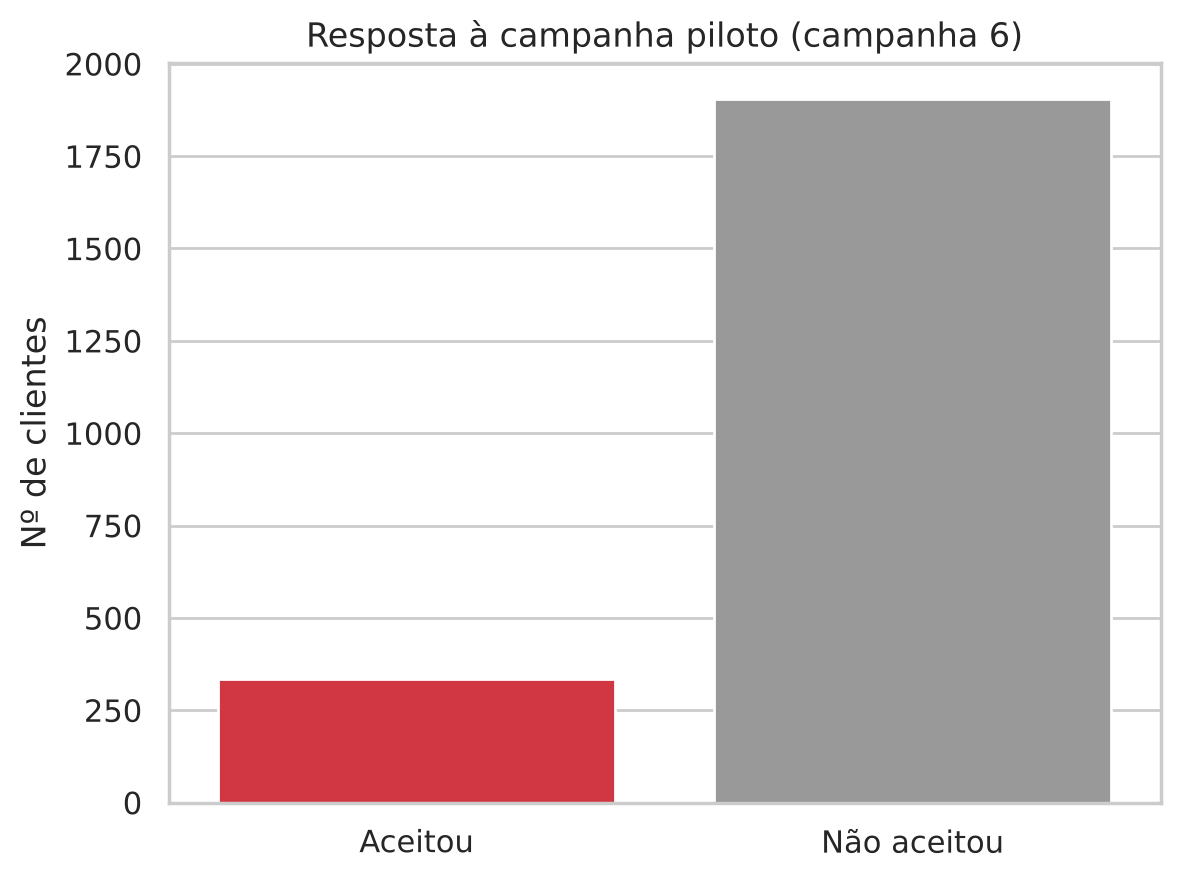

In [5]:
df["Resultado"] = df["Response"].map({0: "Não aceitou", 1: "Aceitou"})
print(f"Taxa de aceite da campanha piloto: {df['Response'].mean() * 100:.1f}%")

ax = sns.countplot(data=df, x="Resultado", hue="Resultado", palette=cores, legend=False)
ax.set_title("Resposta à campanha piloto (campanha 6)")
ax.set_xlabel("")
ax.set_ylabel("Nº de clientes")
plt.show()

Mediana de cada grupo:


Resultado,Aceitou,Não aceitou
Income,64090.0,50150.0
Recency,30.0,52.0
Gasto_Total,1057.5,314.0
Campanhas_Aceitas,1.0,0.0
Kidhome,0.0,0.0
Teenhome,0.0,1.0


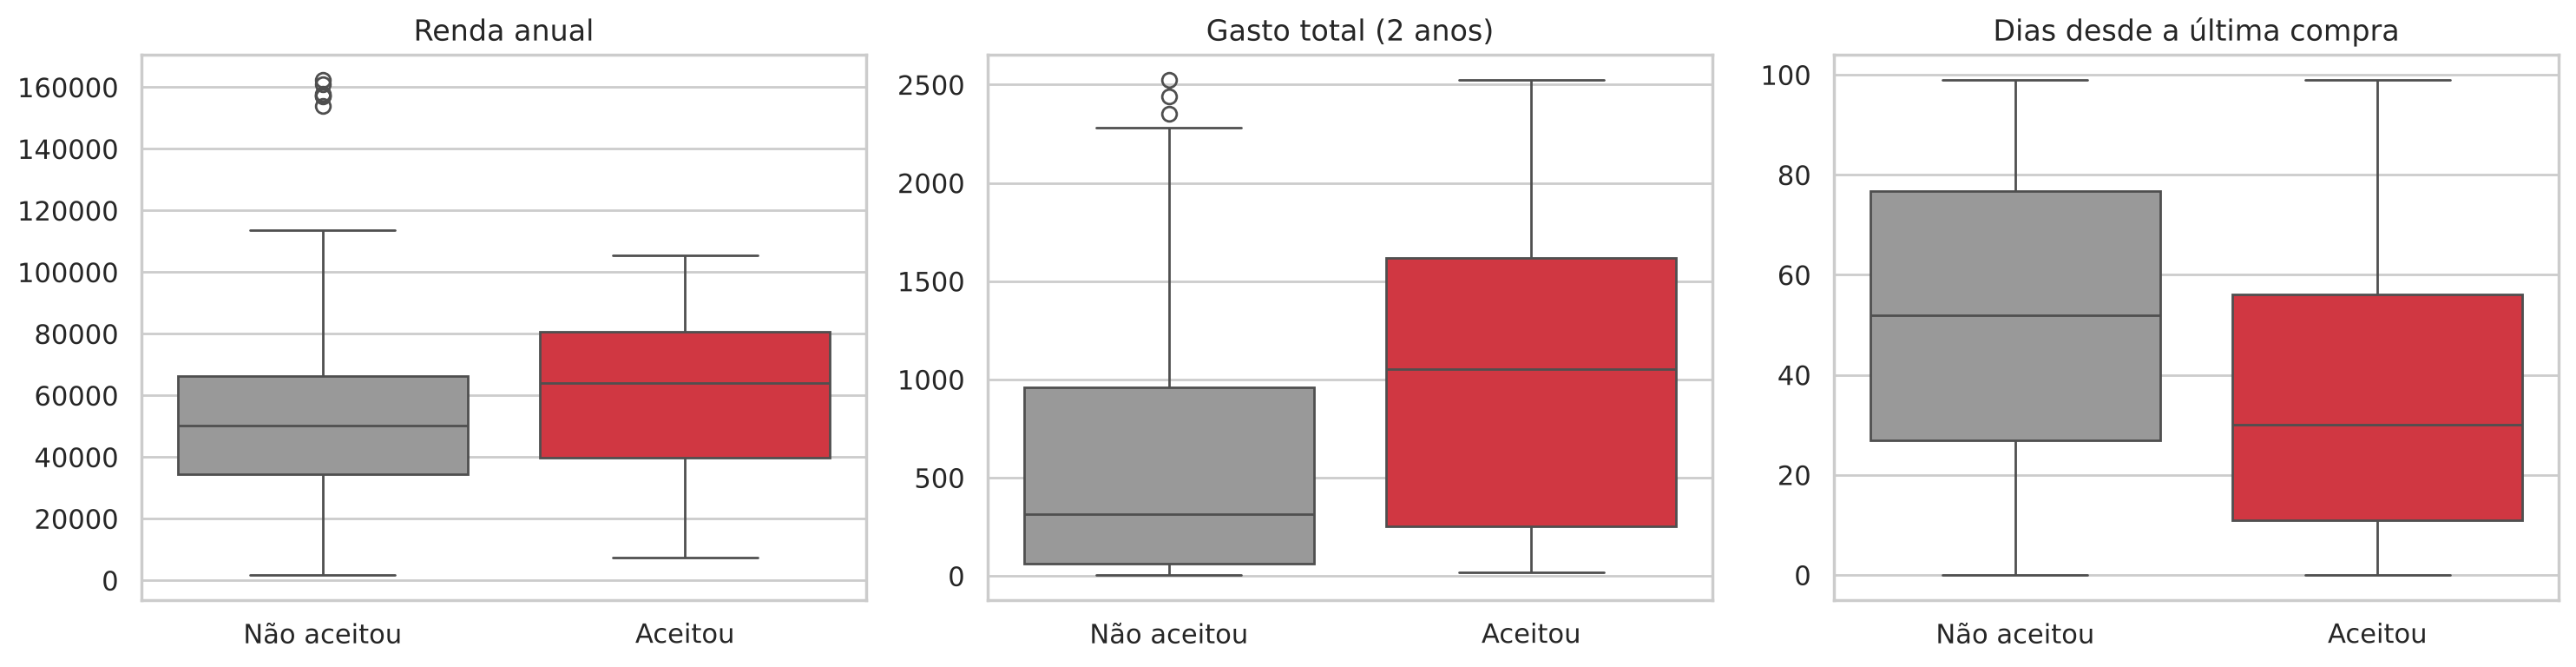

In [6]:
produtos = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
campanhas = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
df["Gasto_Total"] = df[produtos].sum(axis=1)
df["Campanhas_Aceitas"] = df[campanhas].sum(axis=1)

comparacao = df.groupby("Resultado")[["Income", "Recency", "Gasto_Total", "Campanhas_Aceitas", "Kidhome", "Teenhome"]].median()
print("Mediana de cada grupo:")
display(comparacao.T)

dados = df[df["Income"] < 200000]  # tira a renda de 666.666 só para o gráfico ficar legível
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna, titulo in zip(eixos, ["Income", "Gasto_Total", "Recency"],
                              ["Renda anual", "Gasto total (2 anos)", "Dias desde a última compra"]):
    sns.boxplot(data=dados, x="Resultado", y=coluna, hue="Resultado",
                order=["Não aceitou", "Aceitou"], palette=cores, legend=False, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Campanhas_Aceitas
0     8.2
1    31.1
2    50.6
3    79.5
4    90.9
Name: Response, dtype: float64


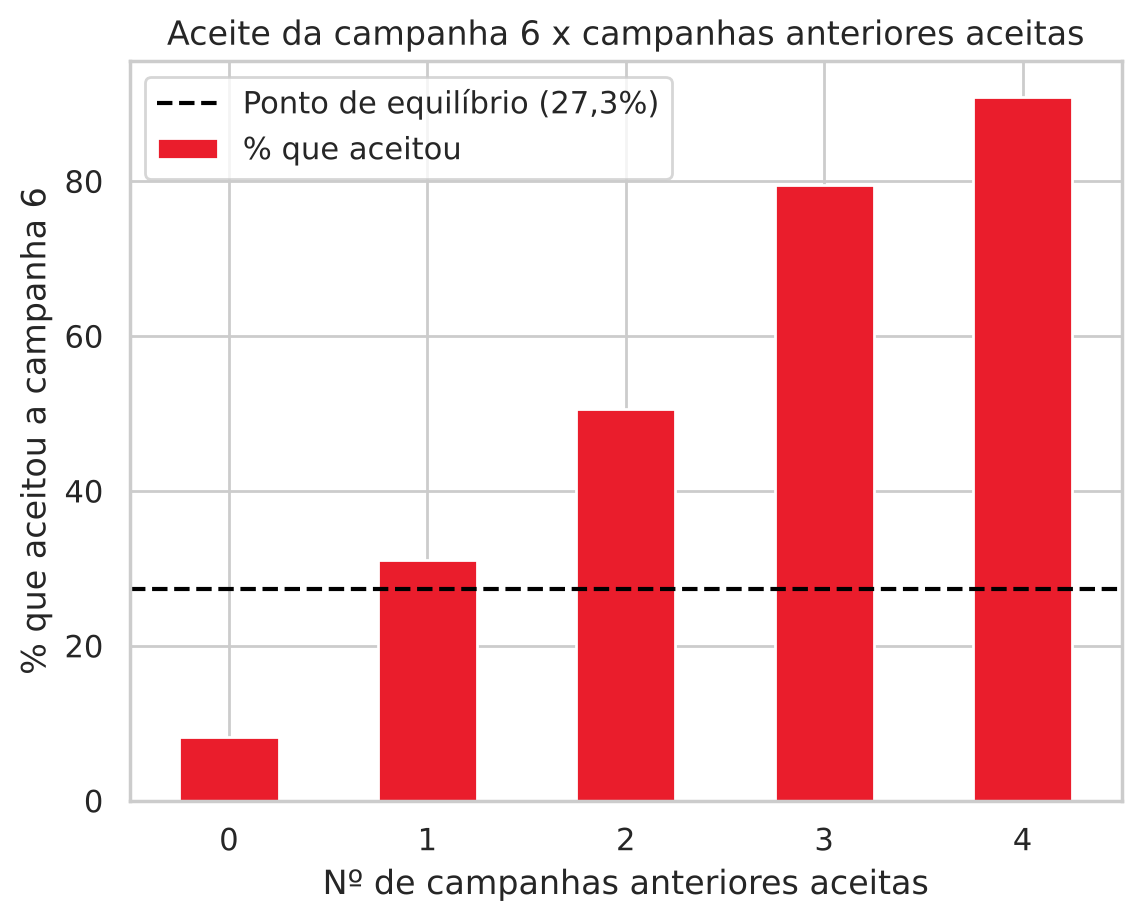

In [7]:
taxa = df.groupby("Campanhas_Aceitas")["Response"].mean() * 100
print(taxa.round(1))

ax = taxa.plot(kind="bar", color="#EA1D2C", label="% que aceitou")
ax.axhline(27.3, color="black", linestyle="--", label="Ponto de equilíbrio (27,3%)")
ax.set_title("Aceite da campanha 6 x campanhas anteriores aceitas")
ax.set_xlabel("Nº de campanhas anteriores aceitas")
ax.set_ylabel("% que aceitou a campanha 6")
ax.legend()
plt.xticks(rotation=0)
plt.show()

### Primeiras hipóteses
Comparando quem aceitou com quem não aceitou (medianas):
- **Renda:** quem aceitou ganha mais (64 mil contra 50 mil por ano)
- **Gasto:** quem aceitou gastou cerca de 3,4 vezes mais nos últimos 2 anos (1.057 contra 314)
- **Recência:** quem aceitou comprou há menos tempo (30 dias contra 52)
- **Filhos:** quem aceitou tende a não ter adolescentes em casa
- **Histórico de campanhas:** é o sinal mais forte. Quem nunca aceitou uma campanha aceitou a 6 em só 8% dos casos. Com 1 campanha anterior aceita, a taxa sobe para 31%, já acima do ponto de equilíbrio. Com 3 ou mais, passa de 79%.

**Hipótese principal:** clientes de renda mais alta, que gastam mais, compraram recentemente e já aceitaram campanhas antes são os que valem o contato.

## Fase 3 — Preparação dos Dados
Nesta fase vamos:
1. **Limpar:** corrigir ou remover os problemas encontrados na Fase 2
2. **Transformar:** criar novas variáveis que ajudam a explicar o comportamento do cliente
3. **Formatar:** deixar a tabela só com números, no formato que o modelo precisa

In [8]:
# Trabalhamos numa cópia para manter os dados originais intactos
dados = df.copy()
print("Clientes no início:", len(dados))

Clientes no início: 2240


In [9]:
# 1. Duplicados: clientes iguais em tudo, menos no ID
colunas_sem_id = dados.columns.drop("ID")
dados = dados.drop_duplicates(subset=colunas_sem_id)
print("Depois de remover duplicados:", len(dados))

# 2. Contraditórios: mesmo cliente aparece duas vezes, uma aceitando e outra não
colunas_cliente = dados.columns.drop(["ID", "Response", "Resultado"])
contraditorios = dados.duplicated(subset=colunas_cliente, keep=False)
print("Registros contraditórios:", contraditorios.sum())
dados = dados[~contraditorios]
print("Depois de remover os contraditórios:", len(dados))

# 3. Estado civil: "Alone" vira "Single"; "Absurd" e "YOLO" saem
dados = dados[~dados["Marital_Status"].isin(["Absurd", "YOLO"])]
dados["Marital_Status"] = dados["Marital_Status"].replace({"Alone": "Single"})
print("Depois de corrigir o estado civil:", len(dados))

# 4. Idades impossíveis (nascidos antes de 1920)
dados = dados[dados["Year_Birth"] >= 1920]
print("Depois de remover idades impossíveis:", len(dados))

# 5. Renda absurda (666.666); os clientes sem renda ficam, por enquanto
dados = dados[(dados["Income"] < 200000) | (dados["Income"].isna())]
print("Depois de remover a renda de 666.666:", len(dados))

# 6. Renda vazia: preenchemos com a mediana
mediana_renda = dados["Income"].median()
dados["Income"] = dados["Income"].fillna(mediana_renda)
print(f"Rendas vazias preenchidas com a mediana: {mediana_renda:,.0f}")
print("Valores ausentes restantes:", dados.isna().sum().sum())

Depois de remover duplicados: 2058
Registros contraditórios: 38
Depois de remover os contraditórios: 2020
Depois de corrigir o estado civil: 2018
Depois de remover idades impossíveis: 2015
Depois de remover a renda de 666.666: 2014
Rendas vazias preenchidas com a mediana: 51,524
Valores ausentes restantes: 0


### Decisões de limpeza
- **Duplicados (182):** o mesmo cliente contado duas vezes distorceria as médias e o modelo.
- **Contraditórios (38):** 19 clientes aparecem duas vezes, uma vez aceitando e outra recusando. Não dá para saber qual registro é o certo, então removemos os dois. *(Esse problema não aparece no notebook de referência.)*
- **Estado civil:** "Alone" (sozinho) é equivalente a "Single". "Absurd" e "YOLO" não têm significado, então os clientes saíram.
- **Idades impossíveis:** 3 clientes nascidos em 1893, 1899 e 1900, provável erro de digitação.
- **Renda de 666.666:** muito acima de todo o resto, provável erro.
- **Renda vazia (24 clientes):** preenchemos com a **mediana**, e não com a média, porque a mediana não é puxada por valores extremos.

**Resultado:** de 2.240 para **2.014 clientes**, sem nenhum valor vazio.

In [10]:
# A base termina em junho de 2014, então calculamos idade e tempo de cliente naquela data
data_referencia = pd.to_datetime(dados["Dt_Customer"]).max()

dados["Idade"] = data_referencia.year - dados["Year_Birth"]
dados["Meses_Cliente"] = ((data_referencia - pd.to_datetime(dados["Dt_Customer"])).dt.days / 30.44).round()
dados["Filhos"] = dados["Kidhome"] + dados["Teenhome"]
dados["Mora_com_Parceiro"] = dados["Marital_Status"].isin(["Married", "Together"]).astype(int)
dados["Escolaridade"] = dados["Education"].map({"Basic": 1, "Graduation": 2, "2n Cycle": 3, "Master": 3, "PhD": 4})
dados["Total_Compras"] = dados[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
# clip(lower=1) evita divisão por zero em quem não tem compras registradas
dados["Gasto_por_Compra"] = (dados["Gasto_Total"] / dados["Total_Compras"].clip(lower=1)).round(2)

novas = ["Idade", "Meses_Cliente", "Filhos", "Mora_com_Parceiro", "Escolaridade", "Total_Compras", "Gasto_por_Compra"]
dados[novas].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
Idade,2014.0,45.2,11.7,18.0,37.0,44.0,55.0,74.0
Meses_Cliente,2014.0,11.5,6.6,0.0,6.0,11.5,17.0,23.0
Filhos,2014.0,1.0,0.7,0.0,0.0,1.0,1.0,3.0
Mora_com_Parceiro,2014.0,0.6,0.5,0.0,0.0,1.0,1.0,1.0
Escolaridade,2014.0,2.7,0.8,1.0,2.0,2.0,3.0,4.0
Total_Compras,2014.0,12.5,7.2,0.0,6.0,12.0,18.0,32.0
Gasto_por_Compra,2014.0,38.2,47.4,2.7,13.0,29.6,49.5,1679.0


### Novas variáveis (Feature Engineering)
| Variável | Como foi criada | Por que importa para o marketing |
|---|---|---|
| `Gasto_Total` | Soma dos gastos nas 6 categorias *(criada na Fase 2)* | Valor do cliente |
| `Campanhas_Aceitas` | Soma das campanhas 1 a 5 aceitas *(criada na Fase 2)* | Histórico de resposta |
| `Idade` | 2014 − ano de nascimento | Perfil demográfico |
| `Meses_Cliente` | Meses entre o cadastro e jun/2014 | Fidelidade |
| `Filhos` | Crianças + adolescentes em casa | Momento de vida |
| `Mora_com_Parceiro` | 1 se casado ou morando junto | Perfil do domicílio |
| `Escolaridade` | Básico = 1, Graduação = 2, Mestrado = 3, Doutorado = 4 | Transforma texto em número |
| `Total_Compras` | Compras no site + catálogo + loja | Frequência |
| `Gasto_por_Compra` | Gasto total ÷ total de compras | Ticket médio |

*Consideramos "2n Cycle" equivalente a mestrado, como no sistema europeu de ensino.*

In [11]:
# Tiramos o que não serve ao modelo: identificador, texto, data e colunas com um valor só
remover = ["ID", "Year_Birth", "Education", "Marital_Status", "Dt_Customer",
           "Z_CostContact", "Z_Revenue", "Resultado"]
dados_modelo = dados.drop(columns=remover)

print("Formato final (linhas, colunas):", dados_modelo.shape)
print("\nTipos de dados:")
print(dados_modelo.dtypes.value_counts())
print(f"\nTaxa de aceite na base limpa: {dados_modelo['Response'].mean() * 100:.1f}%")

dados_modelo.to_csv("dados_preparados.csv", index=False)
print("\nArquivo dados_preparados.csv salvo!")

Formato final (linhas, colunas): (2014, 31)

Tipos de dados:
int64      28
float64     3
Name: count, dtype: int64

Taxa de aceite na base limpa: 14.5%

Arquivo dados_preparados.csv salvo!


### Resumo da Fase 3
- **2.014 clientes** e **31 colunas**, todas numéricas e sem valores vazios
- Taxa de aceite na base limpa: **14,5%** (293 clientes)
- Base salva em `dados_preparados.csv`, pronta para a modelagem

## Fase 4 — Modelagem
Vamos ensinar o computador a prever quem aceita a campanha.

1. **Separar os dados:** o modelo estuda com 70% dos clientes (treino) e faz a "prova" com os outros 30% (teste), que ele nunca viu.
2. **Testar dois algoritmos:** Regressão Logística e Árvore de Decisão.
3. **Refinar:** testar várias configurações de cada algoritmo e ficar com a melhor.
4. **Comparar:** ver qual dos dois acerta mais na prova.

In [12]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, ConfusionMatrixDisplay)

In [13]:
X = dados_modelo.drop(columns="Response")  # características do cliente
y = dados_modelo["Response"]               # o que queremos prever

# stratify=y mantém a mesma proporção de quem aceitou nos dois grupos
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print("Treino:", len(X_treino), "clientes | Teste:", len(X_teste), "clientes")
print(f"Taxa de aceite no treino: {y_treino.mean()*100:.1f}% | no teste: {y_teste.mean()*100:.1f}%")

Treino: 1409 clientes | Teste: 605 clientes
Taxa de aceite no treino: 14.5% | no teste: 14.5%


### Dados desbalanceados
Só 14,5% dos clientes aceitaram. Um modelo "preguiçoso", que sempre diz "não vai aceitar", acertaria 85% das vezes e não serviria para nada.
Para evitar isso, usamos `class_weight="balanced"`: o modelo dá mais peso aos clientes que aceitaram, que são justamente os que queremos encontrar.

In [14]:
# A regressão logística calcula a probabilidade de cada cliente aceitar.
# StandardScaler coloca todas as variáveis na mesma escala (renda e nº de filhos, por exemplo).
logistica = make_pipeline(StandardScaler(),
                          LogisticRegression(class_weight="balanced", max_iter=1000))

# Refinamento: testa 4 valores de C com validação cruzada (5 rodadas dentro do treino)
busca_log = GridSearchCV(logistica, {"logisticregression__C": [0.01, 0.1, 1, 10]},
                         cv=5, scoring="roc_auc")
busca_log.fit(X_treino, y_treino)

print("Melhor configuração:", busca_log.best_params_)
print(f"AUC na validação: {busca_log.best_score_:.3f}")

Melhor configuração: {'logisticregression__C': 0.1}
AUC na validação: 0.895


In [15]:
# A árvore cria regras do tipo "se renda > X e campanhas aceitas > Y, então aceita"
arvore = DecisionTreeClassifier(class_weight="balanced", random_state=42)

# Refinamento: testa profundidades e tamanhos mínimos de grupo
busca_arv = GridSearchCV(arvore, {"max_depth": [3, 4, 5, 6, 8],
                                  "min_samples_leaf": [10, 20, 50]},
                         cv=5, scoring="roc_auc")
busca_arv.fit(X_treino, y_treino)

print("Melhor configuração:", busca_arv.best_params_)
print(f"AUC na validação: {busca_arv.best_score_:.3f}")

Melhor configuração: {'max_depth': 6, 'min_samples_leaf': 20}
AUC na validação: 0.813


,Acurácia (%),Precisão (%),Recall (%),AUC
Modelo,,,,
Regressão Logística,84.13,47.40,82.95,0.91
Árvore de Decisão,74.88,32.42,67.05,0.79


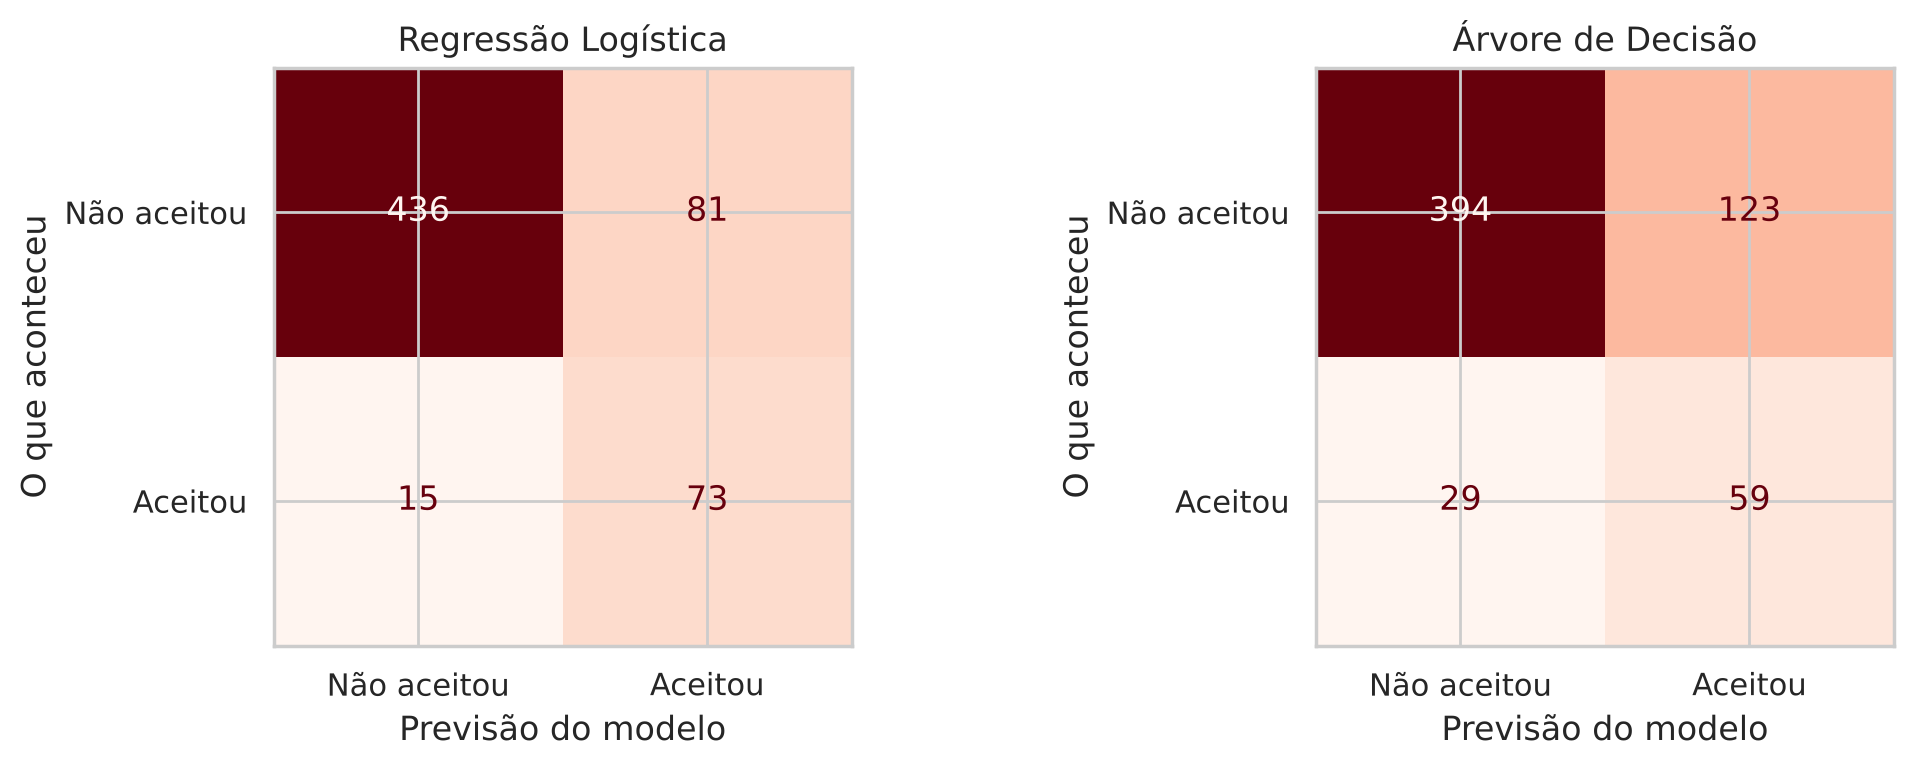

In [16]:
modelos = {"Regressão Logística": busca_log.best_estimator_,
           "Árvore de Decisão": busca_arv.best_estimator_}

linhas = []
for nome, modelo in modelos.items():
    previsao = modelo.predict(X_teste)
    probabilidade = modelo.predict_proba(X_teste)[:, 1]
    linhas.append({"Modelo": nome,
                   "Acurácia (%)": accuracy_score(y_teste, previsao) * 100,
                   "Precisão (%)": precision_score(y_teste, previsao) * 100,
                   "Recall (%)": recall_score(y_teste, previsao) * 100,
                   "AUC": roc_auc_score(y_teste, probabilidade)})
resultados = pd.DataFrame(linhas).set_index("Modelo").round(2)
display(resultados)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, modelo) in zip(eixos, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(modelo, X_teste, y_teste,
        display_labels=["Não aceitou", "Aceitou"], cmap="Reds", colorbar=False, ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("Previsão do modelo")
    ax.set_ylabel("O que aconteceu")
plt.tight_layout()
plt.show()

### Como ler as métricas (em linguagem de marketing)
- **Acurácia:** % de acertos geral. Engana quando a base é desbalanceada.
- **Precisão:** dos clientes que o modelo mandou contatar, quantos aceitaram. **É a taxa de aceite da campanha.**
- **Recall:** dos clientes que aceitariam, quantos o modelo encontrou.
- **AUC:** quão bem o modelo ordena os clientes do mais para o menos propenso (0,5 = chute, 1 = perfeito).

### Resultado na prova (605 clientes de teste)
| Modelo | Acurácia | Precisão | Recall | AUC |
|---|---|---|---|---|
| Regressão Logística | 84,1% | 47,4% | 83,0% | 0,91 |
| Árvore de Decisão | 74,9% | 32,4% | 67,1% | 0,79 |

**A Regressão Logística venceu em todas as métricas.** Dos 605 clientes de teste, ela indicou 154 para contato e 73 deles aceitaram. Dos 88 que aceitariam, deixou passar só 15.

**Modelo escolhido: Regressão Logística.**

## Fase 5 — Avaliação
Agora checamos se o modelo resolve o problema **de negócio**, não só se ele acerta bem:
- [ ] Os resultados do modelo resolvem o problema original (prejuízo da campanha)?
- [ ] Os critérios de sucesso da Fase 1 foram atingidos?

In [17]:
modelo_final = busca_log.best_estimator_
previsao = modelo_final.predict(X_teste)

CUSTO_CONTATO = 3    # custo de cada ligação
RECEITA_VENDA = 11   # receita de cada cliente que aceita

simulacao = pd.DataFrame({
    "Clientes contatados": [len(y_teste), previsao.sum()],
    "Aceitaram": [y_teste.sum(), ((previsao == 1) & (y_teste == 1)).sum()],
}, index=["Ligar para todos", "Só os indicados pelo modelo"])

simulacao["Taxa de aceite (%)"] = (simulacao["Aceitaram"] / simulacao["Clientes contatados"] * 100).round(1)
simulacao["Custo"] = simulacao["Clientes contatados"] * CUSTO_CONTATO
simulacao["Receita"] = simulacao["Aceitaram"] * RECEITA_VENDA
simulacao["Lucro"] = simulacao["Receita"] - simulacao["Custo"]
display(simulacao)

,Clientes contatados,Aceitaram,Taxa de aceite (%),Custo,Receita,Lucro
Ligar para todos,605,88,14.5,1815,968,-847
Só os indicados pelo modelo,154,73,47.4,462,803,341


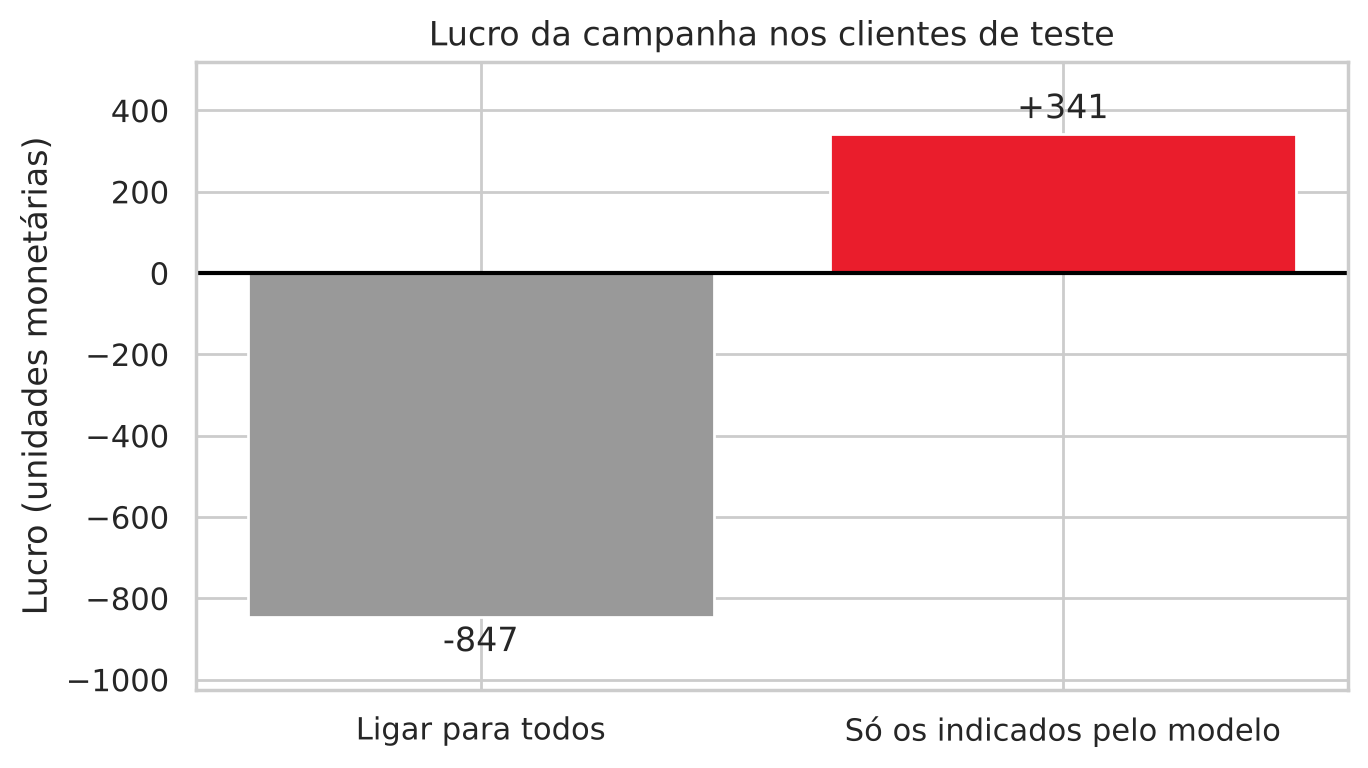

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(simulacao.index, simulacao["Lucro"], color=["#999999", "#EA1D2C"])
ax.bar_label(barras, fmt="%+d", padding=3)
ax.axhline(0, color="black")
ax.set_title("Lucro da campanha nos clientes de teste")
ax.set_ylabel("Lucro (unidades monetárias)")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

In [19]:
precisao = precision_score(y_teste, previsao) * 100
recall = recall_score(y_teste, previsao) * 100

print(f"Critério 1 — taxa de aceite acima de 27,3%: {precisao:.1f}% →",
      "ATINGIDO ✅" if precisao > 27.3 else "NÃO ATINGIDO ❌")
print(f"Critério 2 — encontrar pelo menos 50% dos compradores: {recall:.1f}% →",
      "ATINGIDO ✅" if recall >= 50 else "NÃO ATINGIDO ❌")

Critério 1 — taxa de aceite acima de 27,3%: 47.4% → ATINGIDO ✅
Critério 2 — encontrar pelo menos 50% dos compradores: 83.0% → ATINGIDO ✅


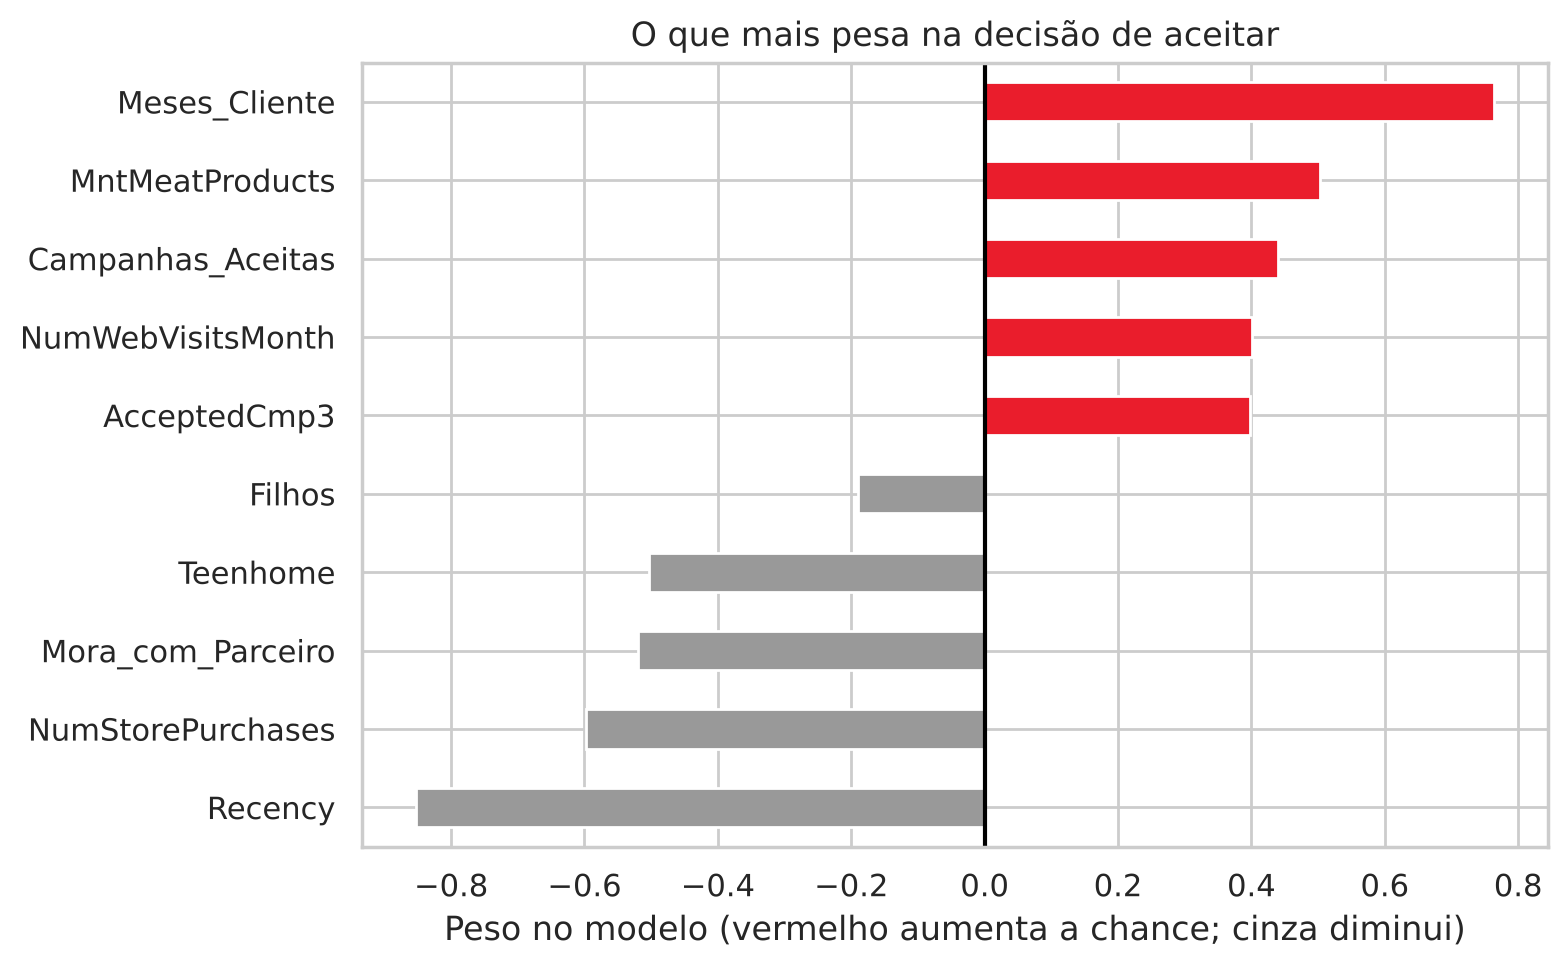

In [20]:
# Como todas as variáveis estão na mesma escala, os pesos podem ser comparados entre si
pesos = pd.Series(modelo_final.named_steps["logisticregression"].coef_[0],
                  index=X.columns).sort_values()
top10 = pd.concat([pesos.head(5), pesos.tail(5)])  # 5 que mais diminuem + 5 que mais aumentam

cores_barras = ["#999999" if v < 0 else "#EA1D2C" for v in top10]
ax = top10.plot(kind="barh", color=cores_barras, figsize=(8, 5))
ax.axvline(0, color="black")
ax.set_title("O que mais pesa na decisão de aceitar")
ax.set_xlabel("Peso no modelo (vermelho aumenta a chance; cinza diminui)")
plt.tight_layout()
plt.show()

### Resultado financeiro (605 clientes de teste)
| | Ligar para todos | Só os indicados pelo modelo |
|---|---|---|
| Clientes contatados | 605 | 154 |
| Aceitaram | 88 | 73 |
| Taxa de aceite | 14,5% | **47,4%** |
| Custo | 1.815 | 462 |
| Receita | 968 | 803 |
| **Lucro** | **−847** | **+341** |

Com o modelo, a empresa faz **75% menos ligações**. Perde 15 vendas, mas a campanha **sai do prejuízo e passa a dar lucro**.

### O que pesa na decisão do cliente
**Aumentam a chance de aceitar:** ser cliente há mais tempo, gastar mais com carnes, ter aceitado campanhas anteriores (principalmente a 3) e visitar mais o site.
**Diminuem a chance:** estar há muito tempo sem comprar, comprar muito na loja física, morar com parceiro(a) e ter filhos, principalmente adolescentes.

*Atenção: algumas variáveis se parecem muito entre si (ex.: `Kidhome`, `Teenhome` e `Filhos`), então o peso de cada uma deve ser lido junto com a análise da Fase 2, não isoladamente.*

### Checklist da avaliação
- [x] **Resolve o problema de negócio?** Sim: transforma o prejuízo de 847 em lucro de 341.
- [x] **Critérios da Fase 1 atingidos?** Sim: taxa de aceite de 47,4% (meta: acima de 27,3%) e 83% dos compradores encontrados (meta: pelo menos 50%).

### Limitações
- Os dados são de 2012 a 2014 e vêm de um case, não de uma operação real.
- O teste tem só 88 compradores. O modelo precisa ser revalidado com novas campanhas.

**Modelo aprovado para a Fase 6 — Implantação.**

## Fase 6 — Implantação
Nesta fase mostramos como o modelo sairia do notebook e passaria a ser usado pela equipe de marketing:
1. **Gerar a lista de contatos** priorizada para a próxima campanha
2. **Plano de implantação:** integração, recomendações, documentação e monitoramento

In [21]:
# Na prática, isso seria rodado na base atual de clientes antes de cada campanha.
# Aqui usamos a base preparada inteira para demonstrar.
base_atual = dados_modelo.drop(columns="Response")

lista = pd.DataFrame({
    "ID": dados["ID"],
    "Pontuacao": (modelo_final.predict_proba(base_atual)[:, 1] * 100).round(1),
})
lista["Prioridade"] = pd.cut(lista["Pontuacao"], bins=[0, 50, 75, 100],
                             labels=["Não contatar", "Média", "Alta"], include_lowest=True)
lista = lista.sort_values("Pontuacao", ascending=False)

print("Clientes por prioridade:")
print(lista["Prioridade"].value_counts())
lista.to_csv("lista_campanha.csv", index=False)
print("\nArquivo lista_campanha.csv salvo!")
lista.head(10)

Clientes por prioridade:
Prioridade
Não contatar    1491
Alta             284
Média            239
Name: count, dtype: int64

Arquivo lista_campanha.csv salvo!


,ID,Pontuacao,Prioridade
21,5376,100.0,Alta
687,1501,100.0,Alta
1845,7872,99.9,Alta
586,9058,99.9,Alta
430,3725,99.9,Alta
252,10089,99.9,Alta
1087,1509,99.9,Alta
336,7381,99.8,Alta
1961,3009,99.8,Alta
2167,3520,99.8,Alta


### Resultado: lista para a próxima campanha
Dos 2.014 clientes, o modelo indica **523 para contato** (26% da base):
- **Alta prioridade (284):** pontuação acima de 75, ligar primeiro
- **Média prioridade (239):** pontuação entre 50 e 75, ligar em seguida
- **Não contatar (1.491)**

*A pontuação vai de 0 a 100 e serve para ordenar os clientes. Ela não é a probabilidade exata de aceite, porque o modelo deu peso extra aos clientes que aceitaram (`class_weight="balanced"`).*

### 1. Integração ao processo de marketing
1. Antes de cada campanha, exportar a base atualizada de clientes do CRM.
2. Aplicar a mesma limpeza da Fase 3 e o modelo treinado.
3. Gerar a lista priorizada (`lista_campanha.csv`) e enviar para a equipe de televendas.
4. A equipe liga primeiro para a prioridade Alta e depois para a Média.
5. O resultado de cada ligação é registrado no CRM e vira dado para treinar o modelo de novo.

### 2. Recomendações de marketing
- **Priorizar quem já aceitou campanhas antes:** é o sinal mais forte de que o cliente vai aceitar de novo.
- **Reativar clientes inativos com canais baratos:** quem está há muito tempo sem comprar raramente aceita. Vale um e-mail de reativação antes de gastar uma ligação.
- **Testar canais digitais:** quem visita muito o site tende a aceitar mais. E-mail e push custam menos que uma ligação, o que diminui o ponto de equilíbrio da campanha.
- **Criar ofertas específicas para famílias com adolescentes e casais:** são os grupos que menos aceitam este produto. Vale testar outra oferta em vez de insistir na mesma.

### 3. Documentação
- Notebook comentado com todas as fases e decisões
- README no GitHub com o resumo do projeto
- Dicionário de dados (Fase 2)
- Ficha do modelo: Regressão Logística (C = 0,1), treinada com 1.409 clientes, AUC 0,91, precisão 47,4%, recall 83%

### 4. Monitoramento e manutenção
| Indicador (a cada campanha) | Meta | Se não atingir |
|---|---|---|
| Taxa de aceite dos contatados | Acima de 27,3% | Revisar o modelo |
| Lucro da campanha | Acima de zero | Revisar o modelo e a oferta |
| Taxa de aceite do grupo de controle | Continuar baixa | O modelo pode estar deixando bons clientes de fora |

- **Grupo de controle:** a cada campanha, ligar também para uma amostra aleatória de 10% dos clientes "Não contatar". Isso mostra se o modelo continua acertando.
- **Retreino:** treinar o modelo de novo a cada campanha nova, ou antes, se a taxa de aceite ficar abaixo da meta por duas campanhas seguidas.

## Conclusão
A campanha piloto ligou para todos os clientes e deu **prejuízo**. Seguindo o CRISP-DM:
- **Fase 1:** definimos que a campanha só dá lucro com mais de 27,3% de aceite.
- **Fases 2 e 3:** encontramos e corrigimos problemas nos dados (duplicados, registros contraditórios, idades e rendas impossíveis) e criamos 9 novas variáveis.
- **Fase 4:** comparamos Regressão Logística e Árvore de Decisão; a logística venceu (AUC 0,91).
- **Fase 5:** na simulação, o modelo reduziu as ligações em 75%, elevou o aceite de 14,5% para 47,4% e transformou um **prejuízo de 847 em lucro de 341**.
- **Fase 6:** o modelo gera uma lista priorizada para cada campanha, com plano de monitoramento e retreino.

**Principal aprendizado de marketing:** ligar para todo mundo é caro. Saber *para quem* ligar vale mais do que aumentar o número de contatos.